In [1]:
data = 'wget https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv'
!wget $data

Prepended http:// to 'wget'
--2026-11-02 21:51:46--  http://wget/
Resolving wget (wget)... failed: Name or service not known.
wget: unable to resolve host address ‘wget’
--2026-11-02 21:51:50--  https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.111.133, 185.199.108.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.111.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 635180 (620K) [text/plain]
Saving to: ‘car_fuel_efficiency_2026.csv’

car_fuel_efficiency 100%[===================>] 620.29K  --.-KB/s    in 0.04s   

2026-11-02 21:51:50 (14.3 MB/s) - ‘car_fuel_efficiency_2026.csv’ saved [635180/635180]

FINISHED --2026-11-02 21:51:50--
Total wall clock time: 4.5s
Downloaded: 1 files, 620K in 0.04s (14.3 MB/s)


In [2]:
import pandas as pd

df_car_fuel = pd.read_csv('car_fuel_efficiency_2026.csv')
df_car_fuel.head()

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,Europe,Gasoline,Front-wheel drive,4,2180,6,243.0,3870,NaN,31.9
1,2008,Europe,Diesel,Front-wheel drive,4,2390,6,272.0,4210,NaN,31.3
2,1996,Asia,Gasoline,Front-wheel drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,Europe,Gasoline,Front-wheel drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,USA,Diesel,Front-wheel drive,3,2580,7,304.0,4510,17.5,31.0


# Preparing the dataset

## Missing values

In [4]:
df_car_fuel.isnull().sum()

model_year               0
origin                   0
fuel_type                0
drivetrain               0
num_doors                0
engine_displacement      0
num_cylinders            0
horsepower             877
vehicle_weight           0
acceleration           264
fuel_efficiency_mpg      0
dtype: int64

In [5]:
#Fill missing values with zeros
df_car_fuel = df_car_fuel.fillna(0)
df_car_fuel.isnull().sum()

model_year             0
origin                 0
fuel_type              0
drivetrain             0
num_doors              0
engine_displacement    0
num_cylinders          0
horsepower             0
vehicle_weight         0
acceleration           0
fuel_efficiency_mpg    0
dtype: int64

# Train/validation/test split

In [6]:
from sklearn.model_selection import train_test_split

df_full_train, df_test = train_test_split(df_car_fuel, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [8]:
y_train = df_train.fuel_efficiency_mpg.values
y_val = df_val.fuel_efficiency_mpg.values
y_test = df_test.fuel_efficiency_mpg.values

del df_train['fuel_efficiency_mpg']
del df_val['fuel_efficiency_mpg']
del df_test['fuel_efficiency_mpg']

# One-hot encoding

In [13]:
from sklearn.feature_extraction import DictVectorizer

train_dict = df_train.to_dict(orient='records')

dv = DictVectorizer(sparse=True)
X_train = dv.fit_transform(train_dict)
X_train.shape

(6000, 16)

In [28]:
val_dict = df_val.to_dict(orient='records')
X_val = dv.transform(val_dict)

test_dict = df_test.to_dict(orient='records')
X_test = dv.transform(test_dict)

In [18]:
dv.get_feature_names_out()

array(['acceleration', 'drivetrain=All-wheel drive',
       'drivetrain=Front-wheel drive', 'drivetrain=Rear-wheel drive',
       'engine_displacement', 'fuel_type=Diesel', 'fuel_type=Gasoline',
       'fuel_type=Hybrid', 'horsepower', 'model_year', 'num_cylinders',
       'num_doors', 'origin=Asia', 'origin=Europe', 'origin=USA',
       'vehicle_weight'], dtype=object)

In [24]:
pd.DataFrame(X_train.toarray(), columns=dv.get_feature_names_out()).head()


,acceleration,drivetrain=All-wheel drive,drivetrain=Front-wheel drive,drivetrain=Rear-wheel drive,engine_displacement,fuel_type=Diesel,fuel_type=Gasoline,fuel_type=Hybrid,horsepower,model_year,num_cylinders,num_doors,origin=Asia,origin=Europe,origin=USA,vehicle_weight
0,19.0,0.0,1.0,0.0,2370.0,0.0,1.0,0.0,284.0,2011.0,6.0,4.0,0.0,0.0,1.0,4280.0
1,18.8,1.0,0.0,0.0,2460.0,1.0,0.0,0.0,288.0,2012.0,6.0,3.0,0.0,0.0,1.0,4580.0
2,20.6,1.0,0.0,0.0,2070.0,0.0,1.0,0.0,230.0,1985.0,6.0,3.0,0.0,1.0,0.0,4150.0
3,0.0,0.0,1.0,0.0,2050.0,1.0,0.0,0.0,249.0,2005.0,5.0,5.0,0.0,1.0,0.0,4120.0
4,17.9,0.0,1.0,0.0,2160.0,0.0,1.0,0.0,241.0,2004.0,6.0,2.0,1.0,0.0,0.0,4020.0


# Q1. Original splitting feature 

In [26]:
from sklearn.tree import DecisionTreeRegressor

dt = DecisionTreeRegressor(max_depth=1)

dt.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",1
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with 

In [27]:
from sklearn.tree import export_text
print(export_text(dt, feature_names=list(dv.get_feature_names_out())))

|--- model_year <= 1997.50
|   |--- value: [28.61]
|--- model_year >  1997.50
|   |--- value: [31.17]



# Q2. RMSE on validation

In [31]:
#Train a random forest regressor with these parameters:
#    n_estimators=10
#    random_state=1
#    n_jobs=-1 (optional - to make training faster)

from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators=10, random_state=1, n_jobs=-1)
rf.fit(X_train, y_train)

y_pred = rf.predict(X_val)
from sklearn.metrics import root_mean_squared_error
RMSE_val = root_mean_squared_error(y_val, y_pred)
RMSE_val


1.8332197358745623

# Q3. Number of estimators

In [36]:
#let's experiment with the n_estimators parameter
# Try these values of this parameter: [10, 50, 100, 150].
# Set random_state to 1.
# Evaluate the model on the validation dataset

scores = []

for n in [10, 50, 100, 150]:
    rf = RandomForestRegressor(n_estimators=n, random_state=1, n_jobs=-1)
    rf.fit(X_train, y_train)
    y_pred = rf.predict(X_val)
    RMSE_val = root_mean_squared_error(y_val, y_pred)
    scores.append((n, RMSE_val))

scores



[(10, 1.8332197358745623),
 (50, 1.7739880309630047),
 (100, 1.7697862961386042),
 (150, 1.7691982356737508)]

# Q4. Best max depth

In [38]:
#Try different values of max_depth: [10, 15, 20, 25]
#For each of these values,
#    try different values of n_estimators from [10, 50, 100, 150]
#    calculate the mean RMSE
#Fix the random seed: random_state=1


scores = []

max_depths = [10, 15, 20, 25]
n_estimators = [10, 50, 100, 150]

for max_depth in max_depths:
    for n_estimator in n_estimators:
        rf = RandomForestRegressor(n_estimators=n_estimator, max_depth=max_depth, random_state=1, n_jobs=-1)
        rf.fit(X_train, y_train)
        y_pred = rf.predict(X_val)
        RMSE_val = root_mean_squared_error(y_val, y_pred)
        scores.append((max_depth, n_estimator, RMSE_val))

scores

[(10, 10, 1.7823475646138716),
 (10, 50, 1.747519928302535),
 (10, 100, 1.7439861944908972),
 (10, 150, 1.7437162901130996),
 (15, 10, 1.8313896883458136),
 (15, 50, 1.770883049718161),
 (15, 100, 1.7678723617281948),
 (15, 150, 1.7667522783622138),
 (20, 10, 1.8373138746453745),
 (20, 50, 1.7723767866064453),
 (20, 100, 1.768917748487332),
 (20, 150, 1.768476341618912),
 (25, 10, 1.8368517467554855),
 (25, 50, 1.7721232000066003),
 (25, 100, 1.76831988647384),
 (25, 150, 1.7679271415004252)]

<Axes: xlabel='n_estimator', ylabel='max_depth'>

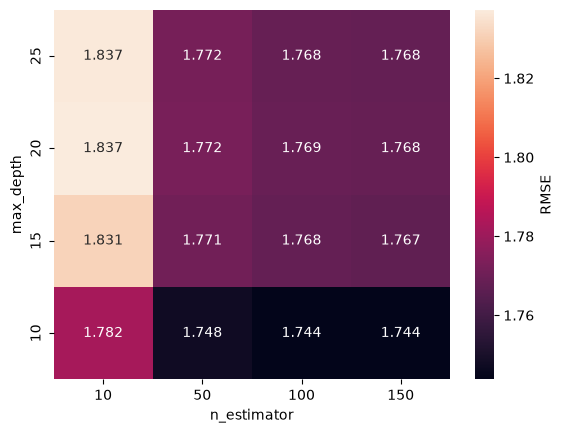

In [44]:
columns = ['max_depth', 'n_estimator', 'RMSE']
df_scores = pd.DataFrame(scores, columns=columns)
df_scores_pivot = df_scores.pivot(index='max_depth', columns='n_estimator', values='RMSE')
df_scores_pivot.round(3)

import seaborn as sns
sns.heatmap(df_scores_pivot.sort_index(ascending=False), annot=True, fmt=".3f", cbar_kws={'label': 'RMSE'})

# Q5. Most important feature

In [46]:
# Train the model with these parameters:
#   n_estimators=10,
#   max_depth=20,
#   random_state=1,
#   n_jobs=-1 (optional)

rf = RandomForestRegressor(n_estimators=10, max_depth=20, random_state=1, n_jobs=-1)
rf.fit(X_train, y_train)

df_importances = pd.DataFrame({
    'feature': dv.get_feature_names_out(),
    'importance': rf.feature_importances_
}).sort_values('importance', ascending=False)

df_importances


,feature,importance
9,model_year,0.296107
15,vehicle_weight,0.203313
6,fuel_type=Gasoline,0.160712
8,horsepower,0.078271
4,engine_displacement,0.061281
0,acceleration,0.054998
14,origin=USA,0.042152
2,drivetrain=Front-wheel drive,0.020062
11,num_doors,0.019401
5,fuel_type=Diesel,0.016571


# Q6. XGBoost eta

In [50]:
# let's train an XGBoost model! For this question, we'll tune the eta parameter:

#    Install XGBoost
import xgboost as xgb

#    Create DMatrix for train and validation
features = list(dv.get_feature_names_out())
dtrain = xgb.DMatrix(X_train, label=y_train, feature_names=features)
dval = xgb.DMatrix(X_val, label=y_val, feature_names=features)

#    Create a watchlist
watchlist = [(dtrain, 'train'), (dval, 'val')]

#    Train a model with these parameters for 100 rounds:
xgb_params = {
    'eta': 0.3, 
    'max_depth': 6,
    'min_child_weight': 1,
    
    'objective': 'reg:squarederror',
    'nthread': 8,
    
    'seed': 1,
    'verbosity': 1,
}

etas = {0.1, 0.3}
xgb_scores = {}

for eta in etas:
    xgb_params['eta'] = eta
    evals_result = {}
  
    model = xgb.train(
        xgb_params, dtrain,
        num_boost_round=100,
        verbose_eval=5,
        evals=watchlist,
        evals_result=evals_result
        )

    xgb_scores[f'eta={eta}'] = pd.DataFrame({
        'num_iter': range(len(evals_result['val']['rmse'])),
        'train_rmse': evals_result['train']['rmse'],
        'val_rmse': evals_result['val']['rmse'],
    })

[0]	train-rmse:2.74739	val-rmse:2.78635
[5]	train-rmse:2.12109	val-rmse:2.20428
[10]	train-rmse:1.80592	val-rmse:1.93152
[15]	train-rmse:1.64286	val-rmse:1.80346
[20]	train-rmse:1.55847	val-rmse:1.75076
[25]	train-rmse:1.50918	val-rmse:1.72751
[30]	train-rmse:1.47544	val-rmse:1.71667
[35]	train-rmse:1.44978	val-rmse:1.71287
[40]	train-rmse:1.43074	val-rmse:1.71289
[45]	train-rmse:1.41543	val-rmse:1.71310
[50]	train-rmse:1.40368	val-rmse:1.71358
[55]	train-rmse:1.39009	val-rmse:1.71570
[60]	train-rmse:1.37884	val-rmse:1.71688
[65]	train-rmse:1.37172	val-rmse:1.71812
[70]	train-rmse:1.36283	val-rmse:1.71919
[75]	train-rmse:1.35099	val-rmse:1.72057
[80]	train-rmse:1.34578	val-rmse:1.72100
[85]	train-rmse:1.33480	val-rmse:1.72192
[90]	train-rmse:1.32546	val-rmse:1.72303
[95]	train-rmse:1.32292	val-rmse:1.72324
[99]	train-rmse:1.31192	val-rmse:1.72481
[0]	train-rmse:2.40653	val-rmse:2.46782
[5]	train-rmse:1.59328	val-rmse:1.76216
[10]	train-rmse:1.47125	val-rmse:1.73205
[15]	train-rmse:1.41

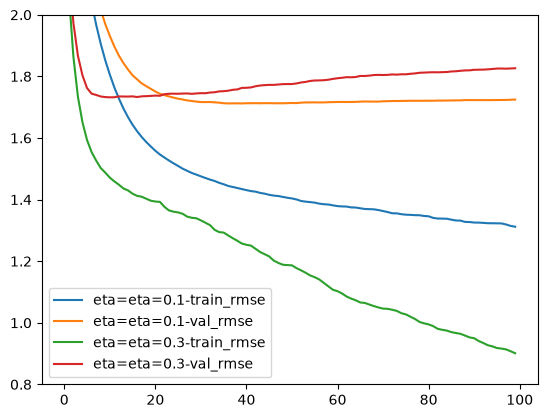

In [55]:
from matplotlib import pyplot as plt
for key, df_score in xgb_scores.items():
    plt.plot(df_score.num_iter, df_score.train_rmse, label=f'eta={key}-train_rmse')
    plt.plot(df_score.num_iter, df_score.val_rmse, label=f'eta={key}-val_rmse')

plt.ylim(0.8, 2)
plt.legend()